# **Voting Regressor on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**Voting Regressor:** several *different* models predict the same sample, and the final prediction is their **average**. Different models make different mistakes, so the average is usually better and more stable than any single model.

Steps:
1. Take 6 different models, each with the **best parameters found earlier** (Poly+Lasso, SVR, KNN, Bagging, Gradient Boosting, LightGBM).
2. Get out-of-fold CV predictions of each model (once).
3. Try **every combination** of models (average of their predictions) and pick the best combination by CV R2.
4. Build the `VotingRegressor` with that combination, test it, and save it as `.pkl`.

### Import

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, VotingRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [4]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### Base Models (with best parameters from the earlier notebooks)

In [5]:
base_models = {
    'Poly+Lasso': Pipeline([('poly', PolynomialFeatures(degree=3, include_bias=False)),
                            ('scaler', StandardScaler()),
                            ('model', Lasso(alpha=0.0316, max_iter=50000))]),

    'SVR': Pipeline([('scaler', StandardScaler()),
                     ('model', SVR(kernel='rbf', C=100, gamma=0.1, epsilon=3))]),

    'KNN': Pipeline([('scaler', StandardScaler()),
                     ('model', KNeighborsRegressor(n_neighbors=4, weights='distance', p=2))]),

    'Bagging': BaggingRegressor(n_estimators=200, random_state=42),

    'GradientBoosting': GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=3,
                                                  subsample=0.85, random_state=42),

    'LightGBM': LGBMRegressor(n_estimators=500, learning_rate=0.2, num_leaves=15, min_child_samples=10,
                              subsample=0.7, subsample_freq=1, reg_lambda=5, random_state=42,
                              n_jobs=1, verbose=-1),
}

### Step 1: CV predictions of every model
`cross_val_predict` gives, for every training row, a prediction made by a model that did **not** see that row. We keep them and reuse them below.

In [6]:
%%time
oof = {}      # out-of-fold predictions of each model
rows = []

for name, model in base_models.items():
    oof[name] = cross_val_predict(model, x_train, y_train, cv=cv, n_jobs=-1)
    rows.append({'Model': name, 'CV_R2': r2_score(y_train, oof[name]), 'CV_MAE': mean_absolute_error(y_train, oof[name])})

single_cv = pd.DataFrame(rows).sort_values('CV_R2', ascending=False).reset_index(drop=True)
single_cv.round(4)

CPU times: total: 391 ms
Wall time: 30.8 s


,Model,CV_R2,CV_MAE
0,LightGBM,0.9335,2.8234
1,GradientBoosting,0.9317,3.0100
2,SVR,0.9138,3.4600
3,Poly+Lasso,0.9089,3.6230
4,Bagging,0.9033,3.7553
5,KNN,0.8705,4.0777


### Step 2: Try every combination (best voting team)
Voting average of a team = average of the members' predictions. We test all teams of 2 or more models and sort by CV R2.

In [7]:
names = list(base_models)
combo_rows = []

for size in range(2, len(names) + 1):
    for team in itertools.combinations(names, size):
        avg_pred = np.mean([oof[n] for n in team], axis=0)
        combo_rows.append({'Team': ' + '.join(team), 'Size': size,
                           'CV_R2': r2_score(y_train, avg_pred),
                           'CV_MAE': mean_absolute_error(y_train, avg_pred)})

combo_df = pd.DataFrame(combo_rows).sort_values('CV_R2', ascending=False).reset_index(drop=True)
print('Teams tested:', len(combo_df))
combo_df.head(10).round(4)

Teams tested: 57


,Team,Size,CV_R2,CV_MAE
0,Poly+Lasso + GradientBoosting + LightGBM,3,0.9402,2.7846
1,SVR + GradientBoosting + LightGBM,3,0.9396,2.7703
2,GradientBoosting + LightGBM,2,0.9387,2.7708
3,Poly+Lasso + SVR + GradientBoosting + LightGBM,4,0.9379,2.8614
4,Poly+Lasso + Bagging + GradientBoosting + Ligh...,4,0.9374,2.8856
5,Poly+Lasso + LightGBM,2,0.9373,2.8670
6,Poly+Lasso + KNN + GradientBoosting + LightGBM,4,0.9372,2.8524
7,SVR + Bagging + GradientBoosting + LightGBM,4,0.9367,2.8827
8,SVR + LightGBM,2,0.9362,2.8457
9,Poly+Lasso + SVR + Bagging + GradientBoosting ...,5,0.9362,2.9278


In [8]:
best_team = combo_df.loc[0, 'Team'].split(' + ')
print('Best voting team:', best_team)
print('Best single model CV R2:', round(single_cv.loc[0, 'CV_R2'], 4), '(' + single_cv.loc[0, 'Model'] + ')')
print('Best voting team CV R2 :', round(combo_df.loc[0, 'CV_R2'], 4))

Best voting team: ['Poly+Lasso', 'GradientBoosting', 'LightGBM']
Best single model CV R2: 0.9335 (LightGBM)
Best voting team CV R2 : 0.9402


### Step 3: Build the VotingRegressor and test it

In [9]:
voting = VotingRegressor([(n, clone(base_models[n])) for n in best_team])
voting.fit(x_train, y_train)
y_pred = voting.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))

MAE  : 2.8897
MSE  : 21.7173
RMSE : 4.6602
R2   : 0.9189


### Voting vs each single model (test set)

In [10]:
rows = []
for name, model in base_models.items():
    p = clone(model).fit(x_train, y_train).predict(x_test)
    rows.append({'Model': name, 'Test_R2': r2_score(y_test, p), 'Test_MAE': mean_absolute_error(y_test, p),
                 'Test_RMSE': np.sqrt(mean_squared_error(y_test, p))})
rows.append({'Model': 'VOTING (' + ' + '.join(best_team) + ')', 'Test_R2': r2, 'Test_MAE': mae, 'Test_RMSE': rmse})

compare = pd.DataFrame(rows).sort_values('Test_R2', ascending=False).reset_index(drop=True)
compare.round(4)

,Model,Test_R2,Test_MAE,Test_RMSE
0,VOTING (Poly+Lasso + GradientBoosting + LightGBM),0.9189,2.8897,4.6602
1,GradientBoosting,0.9119,2.9677,4.8575
2,LightGBM,0.9102,2.8889,4.9054
3,KNN,0.8990,3.6503,5.2014
4,SVR,0.8982,3.6819,5.2206
5,Bagging,0.8779,3.7111,5.7178
6,Poly+Lasso,0.8777,4.2755,5.7237


### Visualization

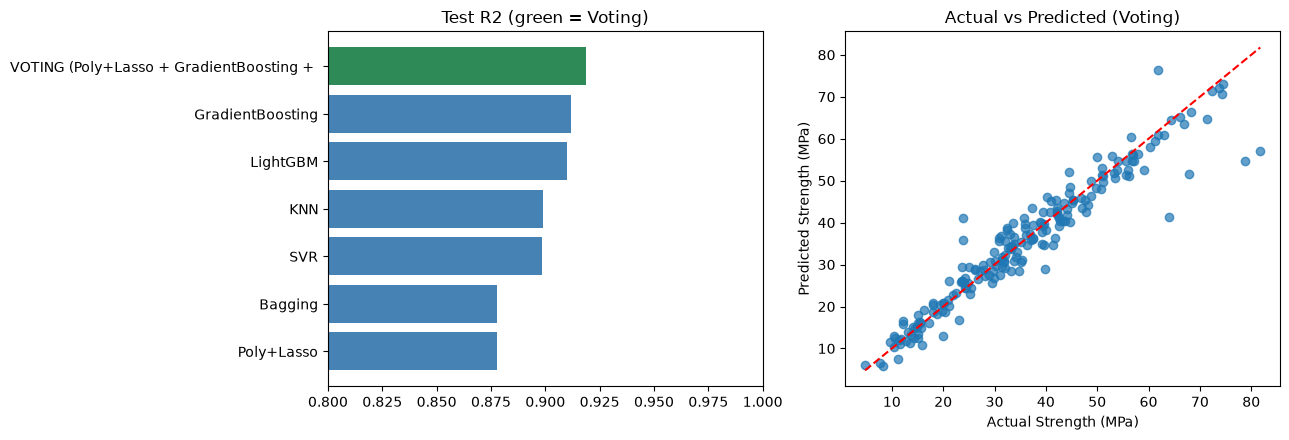

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

#Test R2: single models vs voting
colors = ['seagreen' if m.startswith('VOTING') else 'steelblue' for m in compare['Model']]
ax[0].barh(compare['Model'].str.slice(0, 40), compare['Test_R2'], color=colors)
ax[0].invert_yaxis(); ax[0].set_xlim(0.8, 1)
ax[0].set_title('Test R2 (green = Voting)')

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (Voting)')

plt.tight_layout(); plt.show()

### Save the Model (.pkl)
The voting model is trained once more on all data, then saved with `joblib`.

In [10]:
final_voting = clone(voting)
final_voting.fit(x, y)

joblib.dump(final_voting, 'voting_concrete_model.pkl', compress=3)
combo_df.to_csv('voting_team_results.csv', index=False)
print('Saved: voting_concrete_model.pkl, voting_team_results.csv')

Saved: voting_concrete_model.pkl, voting_team_results.csv


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test R2** above (trained without the test rows).

In [11]:
model = joblib.load('voting_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [22.73 13.75 17.45 29.98 66.91]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [12]:
try:
    from google.colab import files
    files.download('voting_concrete_model.pkl')
    files.download('voting_team_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
